# Punto 2 — Análisis de eventos MAGIC

## 2. Aprendizaje no supervisado: descubrimiento de patrones y agrupamientos

### Objetivo

Identificar estructuras y posibles agrupamientos en las características de **MAGIC Gamma Telescope** mediante tres métodos no supervisados: **K-Means**, **agrupamiento jerárquico (Ward)** y **DBSCAN**. Comparar tanto las métricas de cohesión y separación como la distribución de los grupos, su cobertura y su relación posterior con las clases físicas conocidas.

### Preguntas de investigación

- ¿Qué grupos aparecen cuando los algoritmos **no conocen** si un evento es gamma o hadrónico?
- ¿Cuántos clusters se forman y qué tan separados están?
- ¿Qué diferencias hay entre métodos por centroides, por jerarquía y por densidad?
- ¿Un buen índice Silhouette significa necesariamente que se recuperaron las clases gamma/hadrón?

### Alcance de este notebook

Este archivo es la **continuación de `03_optimizacion_magic.ipynb`**. Lee los CSV e imágenes generados previamente por los programas en `src/punto_2/no_supervisado/`; **no vuelve a ejecutar K-Means, Ward ni DBSCAN**. Cada sección contiene resultados, visualizaciones e interpretación.

## 1. Configuración del entorno

Usaremos el mismo kernel `.venv` de los notebooks anteriores. Los scripts que implementan los modelos permanecen en `src/`; este notebook solo utiliza sus resultados guardados en `resultados/punto_2/no_supervisado/`.

La primera celda identifica la raíz del proyecto tanto si VS Code ejecuta Jupyter desde `notebooks/` como si lo hace desde la carpeta principal.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ubicacion = Path.cwd().resolve()
RAIZ = next(
    (p for p in [ubicacion, *ubicacion.parents] if (p / "src" / "punto_2").is_dir()),
    None
)
if RAIZ is None:
    raise RuntimeError(
        "No se encontró la raíz del proyecto (src/punto_2). "
        "Abre Proyecto_Machine_Learning en VS Code."
    )

if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

BASE = RAIZ / "resultados" / "punto_2" / "no_supervisado"
DATOS_MAGIC = RAIZ / "data" / "raw" / "magic.csv"

print("Raíz del proyecto:", RAIZ)
print("Python:", sys.executable)
print("Resultados no supervisados:", BASE)

Raíz del proyecto: C:\Users\Santiago\Documents\Santiago\Proyectos\Proyecto_Machine_Learning
Python: c:\Users\Santiago\Documents\Santiago\Proyectos\Proyecto_Machine_Learning\.venv\Scripts\python.exe
Resultados no supervisados: C:\Users\Santiago\Documents\Santiago\Proyectos\Proyecto_Machine_Learning\resultados\punto_2\no_supervisado


## 2. Evidencia que vamos a utilizar

El trabajo experimental **ya fue ejecutado**. Antes de presentar resultados, comprobamos que los archivos necesarios existan. Si falta alguno, el mensaje indicará el script del proyecto que debes ejecutar; **no hace falta copiar las clases al notebook**.

In [2]:
archivos = {
    "Métricas K-Means": BASE / "kmeans" / "metricas_kmeans.csv",
    "Composición K-Means": BASE / "kmeans" / "composicion_clusters.csv",
    "Métricas Ward": BASE / "jerarquico" / "metricas_jerarquico.csv",
    "Composición Ward": BASE / "jerarquico" / "composicion_clusters.csv",
    "Búsqueda DBSCAN": BASE / "dbscan" / "metricas_dbscan.csv",
    "Selección DBSCAN": BASE / "dbscan" / "mejor_configuracion.csv",
    "Composición DBSCAN": BASE / "dbscan" / "composicion_clusters.csv",
    "Comparación consolidada": BASE / "comparacion" / "resumen_agrupamientos.csv",
    "Composiciones consolidadas": BASE / "comparacion" / "composicion_agrupamientos.csv",
}

inventario = pd.DataFrame([
    {"Archivo": nombre, "Existe": ruta.is_file(), "Ruta relativa": str(ruta.relative_to(RAIZ))}
    for nombre, ruta in archivos.items()
])
display(inventario)

faltantes = [nombre for nombre, ruta in archivos.items() if not ruta.is_file()]
if faltantes:
    raise FileNotFoundError(
        "Faltan archivos: " + ", ".join(faltantes) + ". "
        "Ejecuta, desde la raíz: "
        "python -m src.punto_2.no_supervisado.kmeans; "
        "python -m src.punto_2.no_supervisado.jerarquico; "
        "python -m src.punto_2.no_supervisado.dbscan; "
        "python -m src.punto_2.no_supervisado.comparar_agrupamientos"
    )

,Archivo,Existe,Ruta relativa
0,Métricas K-Means,True,resultados\punto_2\no_supervisado\kmeans\metri...
1,Composición K-Means,True,resultados\punto_2\no_supervisado\kmeans\compo...
2,Métricas Ward,True,resultados\punto_2\no_supervisado\jerarquico\m...
3,Composición Ward,True,resultados\punto_2\no_supervisado\jerarquico\c...
4,Búsqueda DBSCAN,True,resultados\punto_2\no_supervisado\dbscan\metri...
5,Selección DBSCAN,True,resultados\punto_2\no_supervisado\dbscan\mejor...
6,Composición DBSCAN,True,resultados\punto_2\no_supervisado\dbscan\compo...
7,Comparación consolidada,True,resultados\punto_2\no_supervisado\comparacion\...
8,Composiciones consolidadas,True,resultados\punto_2\no_supervisado\comparacion\...


## 3. Base de datos y preparación del experimento

MAGIC contiene **19.020 registros** descritos por **10 características numéricas**. En la fase supervisada, `Class` indicaba eventos **gamma (`g`)** y **hadrónicos (`h`)**. En la fase no supervisada, esa columna **no participa en la creación de los clusters**.

### Procedimiento empleado en los scripts

1. Se conserva la división original de entrenamiento/prueba definida con semilla **42**.
2. Se extrae una muestra reproducible de **3.000 registros de entrenamiento**.
3. Se estandarizan las diez características numéricas mediante `StandardScaler`.
4. Cada algoritmo trabaja sobre **la misma muestra** y el mismo espacio de características.
5. Solo **después** de formar los grupos se consultan las etiquetas gamma/hadrón para describir su composición y calcular el ARI.

> **Diferencia importante:** agrupar no es lo mismo que clasificar. Los números de cluster (`0`, `1`, etc.) son etiquetas arbitrarias; no significan «gamma» ni «hadrón». Tampoco es obligatorio que el mejor agrupamiento tenga exactamente dos grupos solo porque la variable `Class` tenga dos categorías.

In [3]:
if not DATOS_MAGIC.is_file():
    raise FileNotFoundError(f"No existe la base de datos: {DATOS_MAGIC}")

# El CSV del proyecto contiene una fila inicial de metadatos.
magic = pd.read_csv(DATOS_MAGIC, skiprows=1)
magic.columns = magic.columns.str.strip()

if "Class" not in magic.columns:
    raise ValueError("No se encontró la columna Class en magic.csv")

resumen_datos = pd.DataFrame({
    "Medida": ["Registros disponibles", "Características de entrada", "Clases conocidas", "Tamaño de la muestra de agrupamiento"],
    "Valor": [len(magic), magic.shape[1] - 1, magic["Class"].nunique(), 3000],
})
display(resumen_datos)
print("Características:", ", ".join(magic.drop(columns="Class").columns))

,Medida,Valor
0,Registros disponibles,19020
1,Características de entrada,10
2,Clases conocidas,2
3,Tamaño de la muestra de agrupamiento,3000


Características: Flength, Fwidth, Fsize, Fconc, Fconc1, Fasym, Fm3long, Fm3trans, Falpha, Fdist


## 4. ¿Cómo se evalúan los grupos?

| Indicador | ¿Qué mide? | Interpretación preferida |
|---|---|---|
| **Silhouette** | Si cada observación está más próxima a su grupo que a otros grupos | Más alto (máximo teórico 1) |
| **Calinski-Harabasz** | Relación entre la separación de grupos y su dispersión interna | Más alto, **para soluciones comparables** |
| **Davies-Bouldin** | Similitud media entre grupos en función de dispersión y cercanía | Más bajo |
| **Adjusted Rand Index (ARI)** | Coincidencia *posterior* entre clusters y etiquetas verdaderas, corregida por azar | Más próximo a 1; cerca de 0 ≈ azar |
| **Cobertura** | Proporción de observaciones asignadas a un cluster | Mayor, dependiendo del objetivo |
| **Ruido** | Porcentaje de observaciones que DBSCAN marca como `-1` | No tiene un valor ideal universal |
| **Tamaño del cluster menor** | Detecta soluciones con grupos marginales o casi vacíos | Se interpreta según el problema |

**Precauciones metodológicas.** Los Silhouette de K-Means y Ward se estimaron sobre una muestra de hasta **1.000 observaciones** de los 3.000 registros agrupados. En DBSCAN se excluyó el ruido antes de calcular los indicadores internos. Por ello, un valor Silhouette mayor para DBSCAN **no garantiza** una comparación estrictamente equivalente ni un mejor resultado global.

## 5. K-Means: selección del número de clusters

K-Means asigna cada registro al **centroide** más cercano y reajusta repetidamente los centroides. Su criterio interno favorece grupos compactos alrededor de sus centros, lo cual no siempre refleja estructuras complejas o de formas arbitrarias.

Probamos **K = 2, 3, 4, 5 y 6** y escogimos la configuración con mayor **Silhouette**. El valor de ARI se calcula solo para interpretar el resultado, **no** para escoger K.

,k,silhouette,calinski_harabasz,davies_bouldin,ari_externo
0,2,0.2855,1126.6962,1.4536,0.0039
1,3,0.2629,1009.4415,1.3982,0.0614
2,4,0.1916,887.5823,1.5063,0.0437
3,5,0.1964,792.8417,1.5192,0.0405
4,6,0.1914,726.3586,1.5131,0.0874


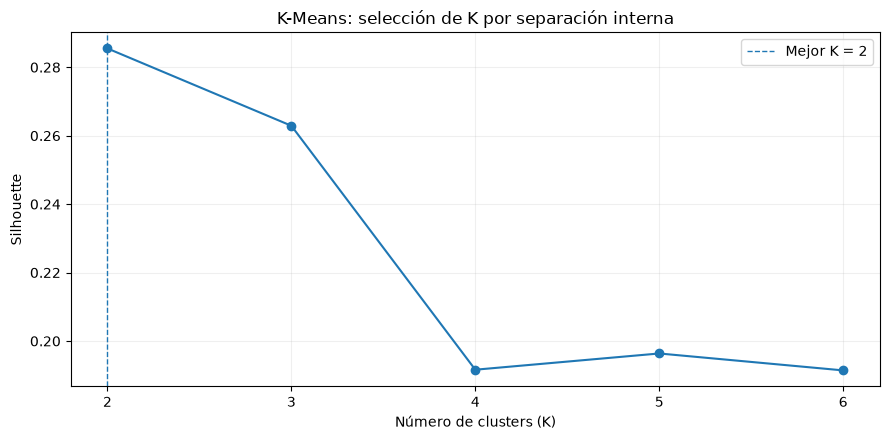

Configuración seleccionada: K = 2; Silhouette = 0.2855


In [4]:
kmeans = pd.read_csv(archivos["Métricas K-Means"]).sort_values("k").reset_index(drop=True)
columnas_k = ["k", "silhouette", "calinski_harabasz", "davies_bouldin", "ari_externo"]
display(kmeans[columnas_k].round(4))

mejor_kmeans = kmeans.loc[kmeans["silhouette"].idxmax()]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(kmeans["k"], kmeans["silhouette"], marker="o")
ax.axvline(int(mejor_kmeans["k"]), linestyle="--", linewidth=1, label=f"Mejor K = {int(mejor_kmeans['k'])}")
ax.set_xticks(kmeans["k"])
ax.set_xlabel("Número de clusters (K)")
ax.set_ylabel("Silhouette")
ax.set_title("K-Means: selección de K por separación interna")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(f"Configuración seleccionada: K = {int(mejor_kmeans['k'])}; Silhouette = {mejor_kmeans['silhouette']:.4f}")

### Interpretación de K-Means

Se seleccionó **K = 2**, con **Silhouette = 0,2855** y Calinski-Harabasz = **1126,70**. La puntuación Silhouette sugiere **separación modesta**, no grupos claramente aislados.

- Con **K = 3**, la separación medida por Silhouette disminuyó a **0,2629**.
- Al incrementar más K, Silhouette se redujo todavía más (alrededor de **0,19**).
- K-Means puede capturar diferencias geométricas globales sin coincidir con las dos clases físicas; la proximidad a un centroide no utiliza las etiquetas verdaderas.

**No debemos interpretar K = 2 como prueba de que el algoritmo reconoció gamma y hadrones.** Esa afirmación requiere examinar la composición de los grupos.

## 6. K-Means: ¿qué contiene cada grupo?

La tabla de composición permite relacionar los grupos encontrados con la clase física real **después** del aprendizaje. Mostramos cantidades y porcentajes para ver si algún cluster está dominado por una clase.

,Cluster,Gamma,Hadron,Total,% Gamma
0,0,756,456,1212,62.38
1,1,1171,617,1788,65.49


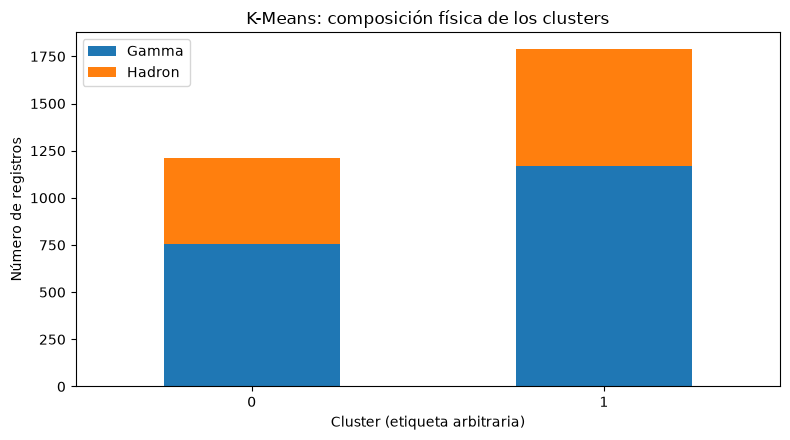

In [5]:
def cargar_composicion(nombre):
    tabla = pd.read_csv(archivos[nombre])
    columnas = {c.strip(): c for c in tabla.columns}
    for requerida in ("Cluster", "Gamma", "Hadron"):
        if requerida not in columnas:
            raise ValueError(f"Falta la columna {requerida} en {nombre}: {list(tabla.columns)}")
    tabla = tabla.rename(columns={columnas[k]: k for k in ("Cluster", "Gamma", "Hadron")})
    tabla["Cluster"] = tabla["Cluster"].astype(int)
    tabla["Gamma"] = tabla["Gamma"].astype(int)
    tabla["Hadron"] = tabla["Hadron"].astype(int)
    tabla["Total"] = tabla["Gamma"] + tabla["Hadron"]
    tabla["% Gamma"] = (100 * tabla["Gamma"] / tabla["Total"]).round(2)
    return tabla.sort_values("Cluster").reset_index(drop=True)

composicion_kmeans = cargar_composicion("Composición K-Means")
display(composicion_kmeans)

ax = composicion_kmeans.set_index("Cluster")[["Gamma", "Hadron"]].plot(
    kind="bar", stacked=True, figsize=(8, 4.5)
)
ax.set_title("K-Means: composición física de los clusters")
ax.set_xlabel("Cluster (etiqueta arbitraria)")
ax.set_ylabel("Número de registros")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### ¿Por qué el ARI de K-Means es tan bajo?

K-Means formó grupos de **1.212** y **1.788** observaciones, pero **ambos mezclan gamma y hadrones**:

- Cluster 0: **756 gamma** y **456 hadrones** (aprox. **62,38 % gamma**).
- Cluster 1: **1.171 gamma** y **617 hadrones** (aprox. **65,49 % gamma**).

Las proporciones de gamma son muy similares entre ambos clusters. Por eso, **ARI = 0,0039**, prácticamente equivalente a una coincidencia ajustada por azar. K-Means separó observaciones según su geometría numérica, pero **esa partición no recuperó las clases físicas**.

## 7. Agrupamiento jerárquico: método Ward

El método jerárquico aglomerativo **empieza con observaciones separadas** y fusiona gradualmente grupos. Con el criterio **Ward**, intenta limitar el aumento de la variación interna en cada fusión.

Se probaron los mismos valores **K = 2 a 6**, utilizando la **misma muestra de 3.000 eventos** y las diez variables estandarizadas.

,k,silhouette,calinski_harabasz,davies_bouldin,ari_externo
0,2,0.3193,935.9599,1.5844,0.0450
1,3,0.1305,726.0086,1.7854,0.0176
2,4,0.1437,667.6085,1.6749,0.0238
3,5,0.1471,610.9572,1.6436,0.0294
4,6,0.1474,585.4797,1.6568,0.0754


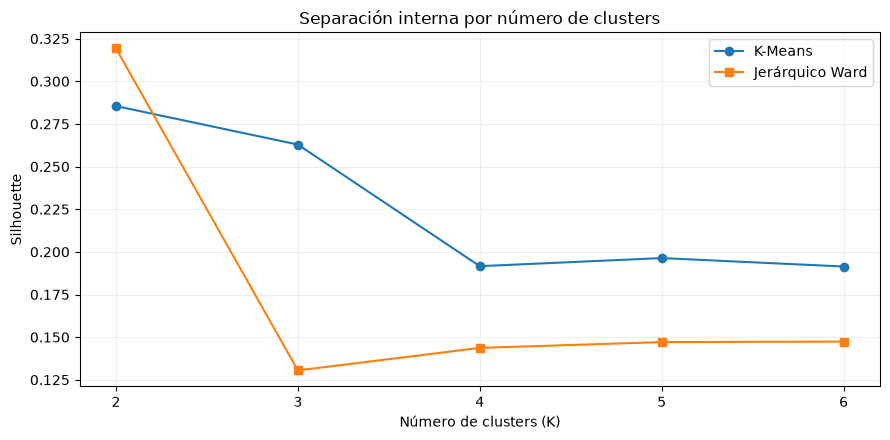

Ward seleccionado: K = 2; Silhouette = 0.3193


In [6]:
ward = pd.read_csv(archivos["Métricas Ward"]).sort_values("k").reset_index(drop=True)
display(ward[columnas_k].round(4))

mejor_ward = ward.loc[ward["silhouette"].idxmax()]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(kmeans["k"], kmeans["silhouette"], marker="o", label="K-Means")
ax.plot(ward["k"], ward["silhouette"], marker="s", label="Jerárquico Ward")
ax.set_xticks(ward["k"])
ax.set_xlabel("Número de clusters (K)")
ax.set_ylabel("Silhouette")
ax.set_title("Separación interna por número de clusters")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(f"Ward seleccionado: K = {int(mejor_ward['k'])}; Silhouette = {mejor_ward['silhouette']:.4f}")

### Interpretación de Ward

Ward seleccionó **K = 2** y obtuvo **Silhouette = 0,3193**, mayor que el **0,2855** de K-Means. Con K = 3, su Silhouette cayó a **0,1305**.

La mayor puntuación de K = 2 indica que, **según Silhouette**, la partición Ward está mejor separada que la de K-Means en esta muestra. Sin embargo:

- K-Means superó a Ward en **Calinski-Harabasz** (**1126,70** frente a **935,96**).
- K-Means también obtuvo **menor Davies-Bouldin** (**1,4536** frente a **1,5844**).

Por eso no existe un ganador único según todas las métricas internas. La diferencia puede deberse a la **forma de construir los grupos**: Ward fusiona grupos minimizando cambios en la variabilidad interna, mientras K-Means reajusta centroides para reducir distancias intragrupo.

## 8. Ward: composición de los clusters

La coincidencia entre los grupos Ward y las clases físicas se evalúa *después del agrupamiento*, utilizando la tabla de composición y ARI.

,Cluster,Gamma,Hadron,Total,% Gamma
0,0,1513,709,2222,68.09
1,1,414,364,778,53.21


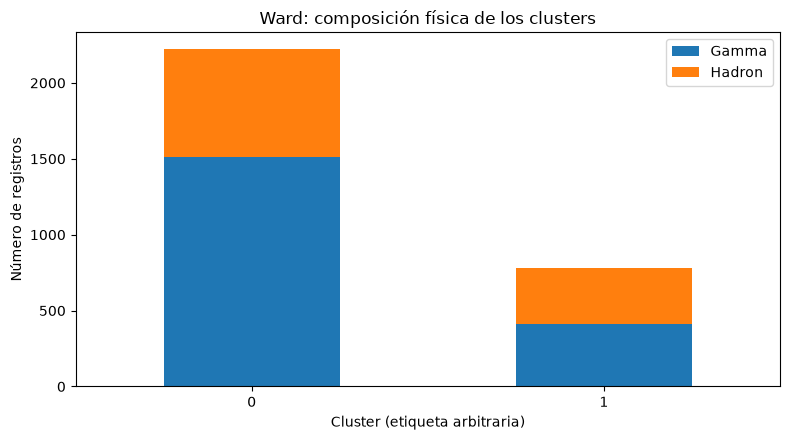

In [7]:
composicion_ward = cargar_composicion("Composición Ward")
display(composicion_ward)

ax = composicion_ward.set_index("Cluster")[["Gamma", "Hadron"]].plot(
    kind="bar", stacked=True, figsize=(8, 4.5)
)
ax.set_title("Ward: composición física de los clusters")
ax.set_xlabel("Cluster (etiqueta arbitraria)")
ax.set_ylabel("Número de registros")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### ¿Qué significa el resultado de Ward?

Ward formó un grupo de **2.222** observaciones (**1.513 gamma y 709 hadrones**) y otro de **778** (**414 gamma y 364 hadrones**). El porcentaje gamma es aproximadamente **68,09 %** en el grupo grande y **53,21 %** en el pequeño.

Hay una diferencia de composición mayor que en K-Means, lo que ayuda a entender que el **ARI de Ward (0,0450)** sea superior al de K-Means (0,0039). Sin embargo, **ambos grupos siguen mezclando clases** y el ARI continúa cerca de cero: la correspondencia es débil.

## 9. DBSCAN: agrupamiento por densidad

DBSCAN utiliza dos parámetros principales:

- **`eps`**: radio máximo para buscar vecinos.
- **`min_samples`**: número mínimo de observaciones para que una zona pueda considerarse suficientemente densa.

A diferencia de K-Means y Ward, DBSCAN no solicita de antemano el número de clusters. Puede asignar `-1` a puntos fuera de las regiones densas (**ruido**).

En el proyecto se probaron **18 combinaciones**: `min_samples = 5, 10, 20` y seis valores de `eps` definidos a partir de cuantiles de distancias a vecinos. El criterio de selección requirió **al menos dos clusters, cobertura de 70 % o más**, y luego eligió la mayor puntuación Silhouette entre las configuraciones elegibles.

In [8]:
dbscan_busqueda = pd.read_csv(archivos["Búsqueda DBSCAN"])
dbscan_elegido = pd.read_csv(archivos["Selección DBSCAN"]).iloc[0]

columnas_db = ["min_samples", "cuantil", "eps", "clusters", "ruido_pct", "silhouette"]
print("Configuraciones evaluadas:", len(dbscan_busqueda))
display(dbscan_busqueda[columnas_db].round(4))

resumen_elegido = pd.DataFrame({
    "Indicador": ["min_samples", "eps", "Clusters", "Cobertura (%)", "Ruido (%)", "Silhouette", "ARI externo"],
    "Valor": [
        int(dbscan_elegido["min_samples"]),
        round(float(dbscan_elegido["eps"]), 4),
        int(dbscan_elegido["clusters"]),
        round(100 * float(dbscan_elegido["cobertura"]), 2),
        round(float(dbscan_elegido["ruido_pct"]), 2),
        round(float(dbscan_elegido["silhouette"]), 4),
        round(float(dbscan_elegido["ari_externo"]), 4),
    ]
})
display(resumen_elegido)

Configuraciones evaluadas: 18


,min_samples,cuantil,eps,clusters,ruido_pct,silhouette
0,5,0.25,0.6894,31,57.7333,-0.1983
1,5,0.40,0.7609,16,42.1333,-0.2204
2,5,0.55,0.8410,4,31.8000,0.1518
3,5,0.70,0.9779,3,22.3000,0.0922
4,5,0.85,1.4195,1,12.2000,NaN
5,5,0.95,2.4700,2,3.1667,0.5450
6,10,0.25,0.7990,11,51.0333,-0.1262
7,10,0.40,0.8769,4,36.1000,0.0029
8,10,0.55,0.9674,1,27.1333,NaN
9,10,0.70,1.1142,1,20.0667,NaN


,Indicador,Valor
0,min_samples,5.0000
1,eps,2.4700
2,Clusters,2.0000
3,Cobertura (%),96.8300
4,Ruido (%),3.1700
5,Silhouette,0.5450
6,ARI externo,0.0516


### ¿Qué ocurre al cambiar `eps` y `min_samples`?

Cuando `eps` es pequeño, muchas observaciones no encuentran vecinos suficientes y pueden aparecer **numerosos grupos pequeños y mucho ruido**. Cuando `eps` crece, regiones separadas pueden conectarse y terminar en **un solo cluster muy grande**.

En estos experimentos ocurrieron ambos comportamientos: con `min_samples = 5` y `eps = 0,6894` aparecieron **31 clusters** y **57,73 % de ruido**; con otros radios se encontró solo un cluster. La selección final llegó a **dos clusters** con cobertura alta, pero es necesario revisar su distribución antes de interpretarla.

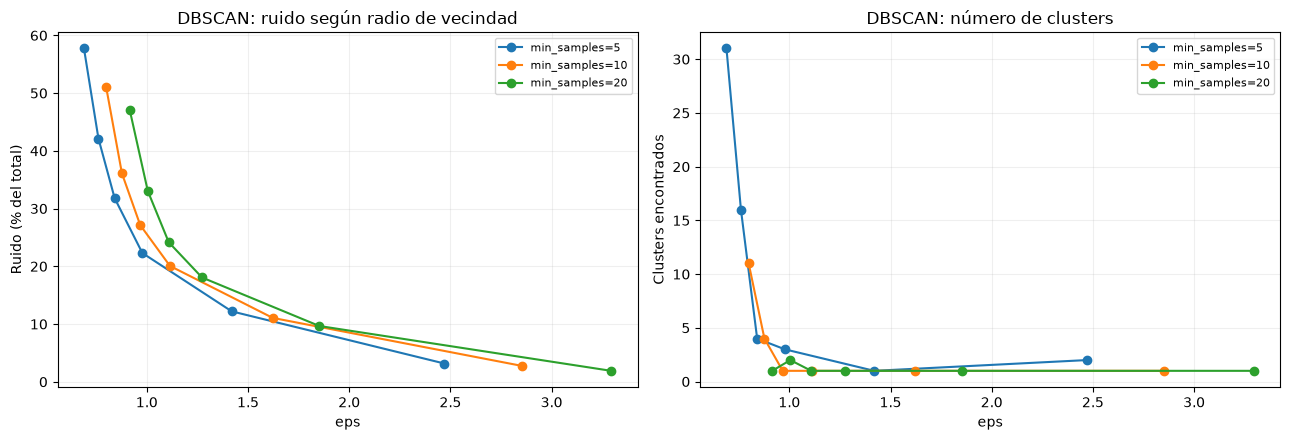

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
for min_samples, grupo in dbscan_busqueda.groupby("min_samples"):
    grupo = grupo.sort_values("eps")
    ejes[0].plot(grupo["eps"], grupo["ruido_pct"], marker="o", label=f"min_samples={min_samples}")
    ejes[1].plot(grupo["eps"], grupo["clusters"], marker="o", label=f"min_samples={min_samples}")

ejes[0].set_title("DBSCAN: ruido según radio de vecindad")
ejes[0].set_xlabel("eps")
ejes[0].set_ylabel("Ruido (% del total)")
ejes[1].set_title("DBSCAN: número de clusters")
ejes[1].set_xlabel("eps")
ejes[1].set_ylabel("Clusters encontrados")
for ax in ejes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 10. DBSCAN: el Silhouette más alto necesita contexto

La configuración elegida fue **`eps = 2,4700`** y **`min_samples = 5`**, con **Silhouette = 0,5450**, **cobertura = 96,83 %** y **ruido = 3,17 %**.

En apariencia, el Silhouette supera al de K-Means y Ward. Sin embargo, **DBSCAN no repartió los datos en dos grupos de tamaño comparable**. Primero debemos examinar cuántas observaciones quedaron en cada uno.

,Cluster,Gamma,Hadron,Total,% Gamma
0,-1,5,90,95,5.26
1,0,1922,978,2900,66.28
2,1,0,5,5,0.00


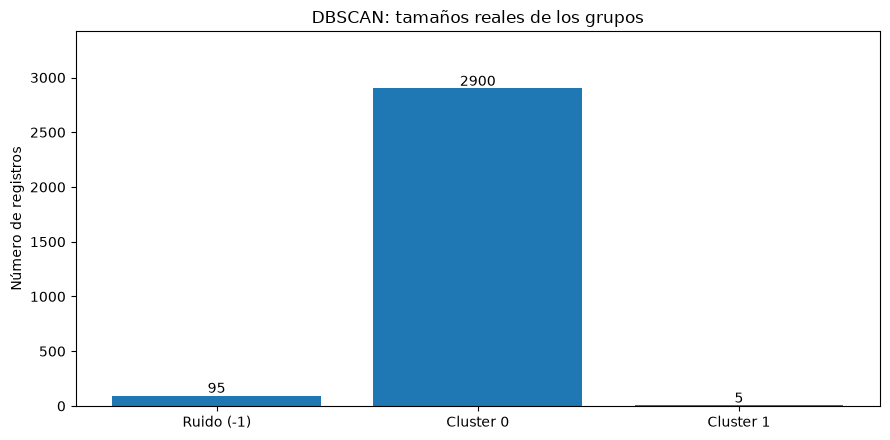

Hadrones entre los registros de ruido: 90/95 (94.74 %)


In [10]:
composicion_dbscan = cargar_composicion("Composición DBSCAN")
display(composicion_dbscan)

fig, ax = plt.subplots(figsize=(9, 4.5))
etiquetas = ["Ruido (-1)" if c == -1 else f"Cluster {c}" for c in composicion_dbscan["Cluster"]]
ax.bar(etiquetas, composicion_dbscan["Total"].to_numpy())
for i, val in enumerate(composicion_dbscan["Total"]):
    ax.text(i, val + 25, str(int(val)), ha="center")
ax.set_ylim(0, float(composicion_dbscan["Total"].max()) * 1.18)
ax.set_title("DBSCAN: tamaños reales de los grupos")
ax.set_ylabel("Número de registros")
plt.tight_layout()
plt.show()

ruido = composicion_dbscan.loc[composicion_dbscan["Cluster"] == -1]
if not ruido.empty:
    print(
        "Hadrones entre los registros de ruido:",
        f"{int(ruido['Hadron'].iloc[0])}/{int(ruido['Total'].iloc[0])}",
        f"({100 * ruido['Hadron'].iloc[0] / ruido['Total'].iloc[0]:.2f} %)"
    )

### ¿Por qué DBSCAN alcanzó 0,5450?

La solución tiene **2.900 registros en el cluster 0**, apenas **5 en el cluster 1** y **95 clasificados como ruido**. Entre los **2.905 puntos agrupados**, el cluster principal representa **99,83 %**. Se trata, por tanto, de **un grupo dominante y un grupo marginal**, no de dos poblaciones extensas claramente separadas.

Un cluster diminuto y distante **puede contribuir a elevar Silhouette** al aumentar la separación entre etiquetas, aunque la estructura global no resulte útil como segmentación. Además, para DBSCAN se calculó Silhouette **sin los 95 puntos de ruido**, por lo que no es una comparación completamente equivalente con K-Means y Ward.

### ¿Qué significa el ruido?

Entre los 95 registros marcados como ruido, **90 son hadrones y 5 son gamma**: el **94,74 % del ruido es hadrónico**. Esto sugiere que, bajo la distancia y los parámetros elegidos, algunos eventos hadrónicos son menos densos o están más alejados de las regiones principales. **No significa que el algoritmo haya identificado correctamente todos los hadrones ni que cualquier hadrón sea anómalo.**

## 11. Comparación cuantitativa de los tres algoritmos

El consolidado recoge las configuraciones previamente seleccionadas y añade **cobertura**, **ruido** y **tamaño del cluster más pequeño**, que son esenciales para no confundir un índice elevado con una partición útil.

In [11]:
comparacion = pd.read_csv(archivos["Comparación consolidada"])
orden = ["K-Means", "Jerarquico Ward", "DBSCAN"]
comparacion = comparacion.set_index("metodo").reindex(orden).reset_index()

columnas_comp = [
    "metodo", "configuracion", "clusters", "silhouette", "calinski_harabasz",
    "davies_bouldin", "ari_externo", "cobertura_pct", "ruido_pct",
    "cluster_minimo", "cluster_minimo_pct"
]
if comparacion[columnas_comp].isna().any().any():
    raise ValueError("El resumen de agrupamientos contiene métodos o métricas faltantes.")
display(comparacion[columnas_comp].round(4))

,metodo,configuracion,clusters,silhouette,calinski_harabasz,davies_bouldin,ari_externo,cobertura_pct,ruido_pct,cluster_minimo,cluster_minimo_pct
0,K-Means,K=2,2,0.2855,1126.6962,1.4536,0.0039,100.0000,0.0000,1212,40.4000
1,Jerarquico Ward,K=2,2,0.3193,935.9599,1.5844,0.0450,100.0000,0.0000,778,25.9333
2,DBSCAN,"eps=2.4700, min_samples=5",2,0.5450,39.3498,0.5288,0.0516,96.8333,3.1667,5,0.1721


### Cómo leer la tabla

- **Silhouette:** DBSCAN tiene la puntuación más alta (**0,5450**), pero excluye ruido y tiene un cluster de solo **5** registros.
- **Cobertura:** K-Means y Ward asignaron el **100 %** de la muestra; DBSCAN asignó el **96,83 %**.
- **Balance:** K-Means tiene un cluster mínimo del **40,40 %**; Ward del **25,93 %**; DBSCAN del **0,17 % de los agrupados**.
- **ARI:** los tres son próximos a cero; la coincidencia con la etiqueta física es baja.

No es correcto ordenar los tres métodos por una única métrica sin considerar sus supuestos y la distribución de sus grupos.

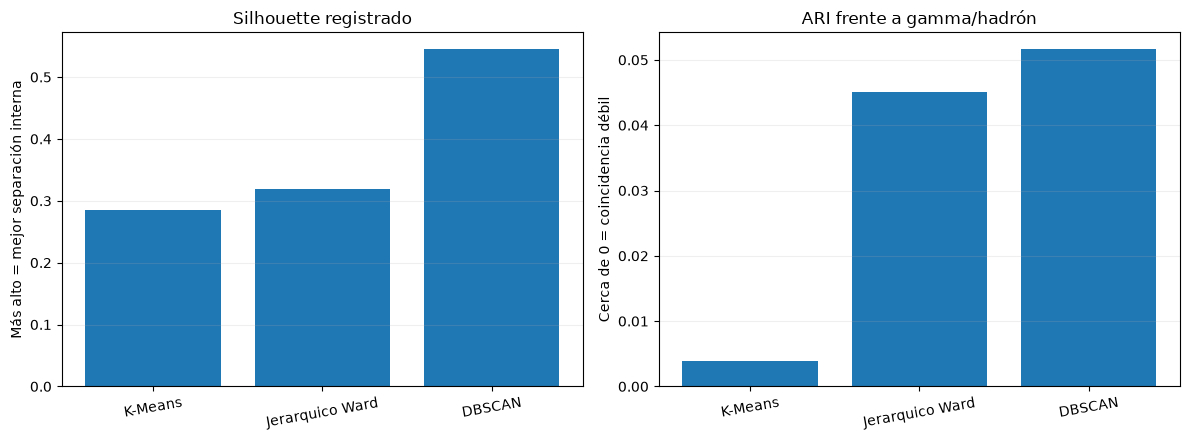

Nota: el Silhouette de DBSCAN excluye el ruido; comparar con precaución.


In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
ejes[0].bar(comparacion["metodo"], comparacion["silhouette"])
ejes[0].set_title("Silhouette registrado")
ejes[0].set_ylabel("Más alto = mejor separación interna")
ejes[1].bar(comparacion["metodo"], comparacion["ari_externo"])
ejes[1].set_title("ARI frente a gamma/hadrón")
ejes[1].set_ylabel("Cerca de 0 = coincidencia débil")
for ax in ejes:
    ax.tick_params(axis="x", rotation=10)
    ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()
print("Nota: el Silhouette de DBSCAN excluye el ruido; comparar con precaución.")

## 12. Comparación del equilibrio y la cobertura

Este gráfico muestra **cuántas observaciones** quedaron en el grupo mayor, en el grupo menor y en el ruido. Ordenamos los grupos por tamaño para evitar suponer que «cluster 0» significa lo mismo entre diferentes algoritmos.

,Grupo mayor,Otros grupos,Ruido
Método,,,
K-Means,1788,1212,0
Jerarquico Ward,2222,778,0
DBSCAN,2900,5,95


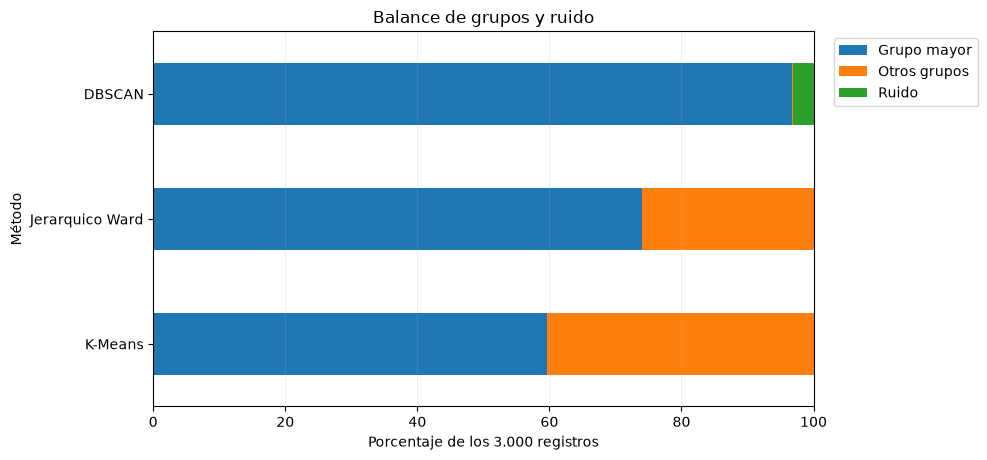

In [13]:
composiciones = pd.read_csv(archivos["Composiciones consolidadas"])
composiciones["Cluster"] = composiciones["Cluster"].astype(int)
composiciones["Total"] = composiciones["Gamma"].astype(int) + composiciones["Hadron"].astype(int)

filas_balance = []
for nombre in orden:
    grupo = composiciones.loc[composiciones["Metodo"] == nombre]
    normales = sorted(
        grupo.loc[grupo["Cluster"] != -1, "Total"].astype(int).tolist(), reverse=True
    )
    ruido_total = int(grupo.loc[grupo["Cluster"] == -1, "Total"].sum())
    filas_balance.append({
        "Método": nombre,
        "Grupo mayor": normales[0],
        "Otros grupos": sum(normales[1:]),
        "Ruido": ruido_total,
    })

balance = pd.DataFrame(filas_balance).set_index("Método")
assert (balance.sum(axis=1) == 3000).all(), "Cada método debe cubrir 3.000 registros."
display(balance)

ax = (100 * balance / balance.sum(axis=1).to_numpy()[:, None]).plot(
    kind="barh", stacked=True, figsize=(10, 4.7)
)
ax.set_xlim(0, 100)
ax.set_xlabel("Porcentaje de los 3.000 registros")
ax.set_title("Balance de grupos y ruido")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

### Interpretación de la distribución

**K-Means** produce dos grupos relativamente equilibrados (**1.788** y **1.212**). **Ward** distingue un grupo mayor y uno menor (**2.222** y **778**). **DBSCAN** concentra **2.900** observaciones en el grupo principal, deja **5** en el secundario y marca **95** como ruido.

La elección entre métodos depende de qué se busca: segmentaciones amplias, jerarquía de similitud o detección de regiones poco densas. Bajo los parámetros evaluados, **K-Means o Ward describen mejor una segmentación de toda la muestra**, mientras que **DBSCAN aporta información sobre observaciones menos densas**, sin ofrecer dos clusters representativos.

## 13. Evaluación externa: ¿los clusters descubren gamma y hadrones?

Una vez finalizado el agrupamiento se compararon los clusters con las clases verdaderas mediante **ARI**. Esto es una **evaluación externa posterior**, no supervisión durante el entrenamiento.

- K-Means: **ARI = 0,0039**.
- Ward: **ARI = 0,0450**.
- DBSCAN: **ARI = 0,0516** (tratando el ruido `-1` como etiqueta adicional).

Todos los valores son bajos; ninguno de los métodos obtuvo una partición que equivalga claramente a las clases físicas. La distribución de etiquetas también muestra mezcla de gamma y hadrones en los grupos principales.

,Método,Grupo,Registros,Gamma (%),Hadrón (%)
0,K-Means,Cluster 0,1212,62.38,37.62
1,K-Means,Cluster 1,1788,65.49,34.51
2,Jerarquico Ward,Cluster 0,2222,68.09,31.91
3,Jerarquico Ward,Cluster 1,778,53.21,46.79
4,DBSCAN,Ruido (-1),95,5.26,94.74
5,DBSCAN,Cluster 0,2900,66.28,33.72
6,DBSCAN,Cluster 1,5,0.00,100.00


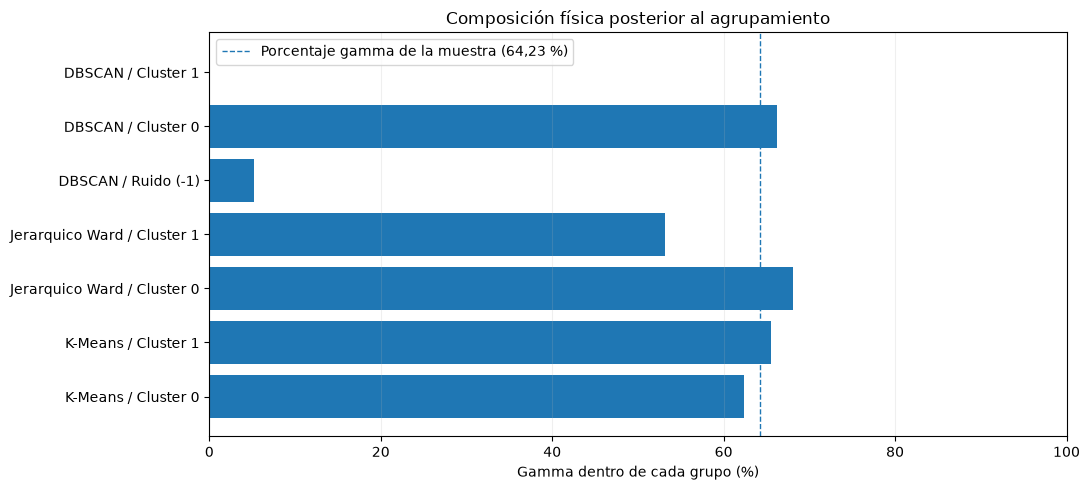

In [14]:
# Resumen de la proporción física por cluster, incluido ruido para DBSCAN.
filas = []
for nombre in orden:
    grupo = composiciones.loc[composiciones["Metodo"] == nombre]
    for _, fila in grupo.iterrows():
        total = int(fila["Total"])
        filas.append({
            "Método": nombre,
            "Grupo": "Ruido (-1)" if int(fila["Cluster"]) == -1 else f"Cluster {int(fila['Cluster'])}",
            "Registros": total,
            "Gamma (%)": 100 * int(fila["Gamma"]) / total,
            "Hadrón (%)": 100 * int(fila["Hadron"]) / total,
        })

composicion_porcentual = pd.DataFrame(filas)
display(composicion_porcentual.round(2))

fig, ax = plt.subplots(figsize=(11, 5))
etiquetas = composicion_porcentual["Método"] + " / " + composicion_porcentual["Grupo"]
valores = composicion_porcentual["Gamma (%)"].to_numpy()
ax.barh(etiquetas, valores)
ax.axvline(100 * 1927 / 3000, linestyle="--", linewidth=1,
           label="Porcentaje gamma de la muestra (64,23 %)")
ax.set_xlim(0, 100)
ax.set_xlabel("Gamma dentro de cada grupo (%)")
ax.set_title("Composición física posterior al agrupamiento")
ax.legend()
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

### Interpretación de la composición física

La muestra contiene **1.927 gamma** y **1.073 hadrones** (aproximadamente **64,23 % gamma**). Los grupos principales de K-Means y Ward tienen proporciones de gamma que no permiten identificarlos directamente con una clase única.

En DBSCAN, los **cinco miembros del segundo cluster son hadrones**, pero es un grupo demasiado pequeño para considerarlo una segmentación general de esa clase. Los **90 hadrones entre los 95 puntos de ruido** son un hallazgo descriptivo interesante que requeriría análisis adicional de sus características y sensibilidad a los parámetros.

> **ARI bajo no equivale a fracaso técnico.** Puede significar que la geometría de las características favorece agrupamientos distintos de las categorías supervisadas; no sabemos la causa exacta solo con estas métricas.

## 14. Visualizaciones PCA guardadas por los experimentos

Los scripts generaron gráficos de clusters proyectados sobre **dos componentes PCA**. Estos gráficos permiten explorar visualmente la forma de los grupos, pero **los tres algoritmos se entrenaron con las 10 características estandarizadas**, no con las dos coordenadas de la figura.

El notebook recupera las imágenes ya guardadas si existen. No se vuelve a ajustar ningún algoritmo de agrupamiento.

### Proyección PCA — K-Means

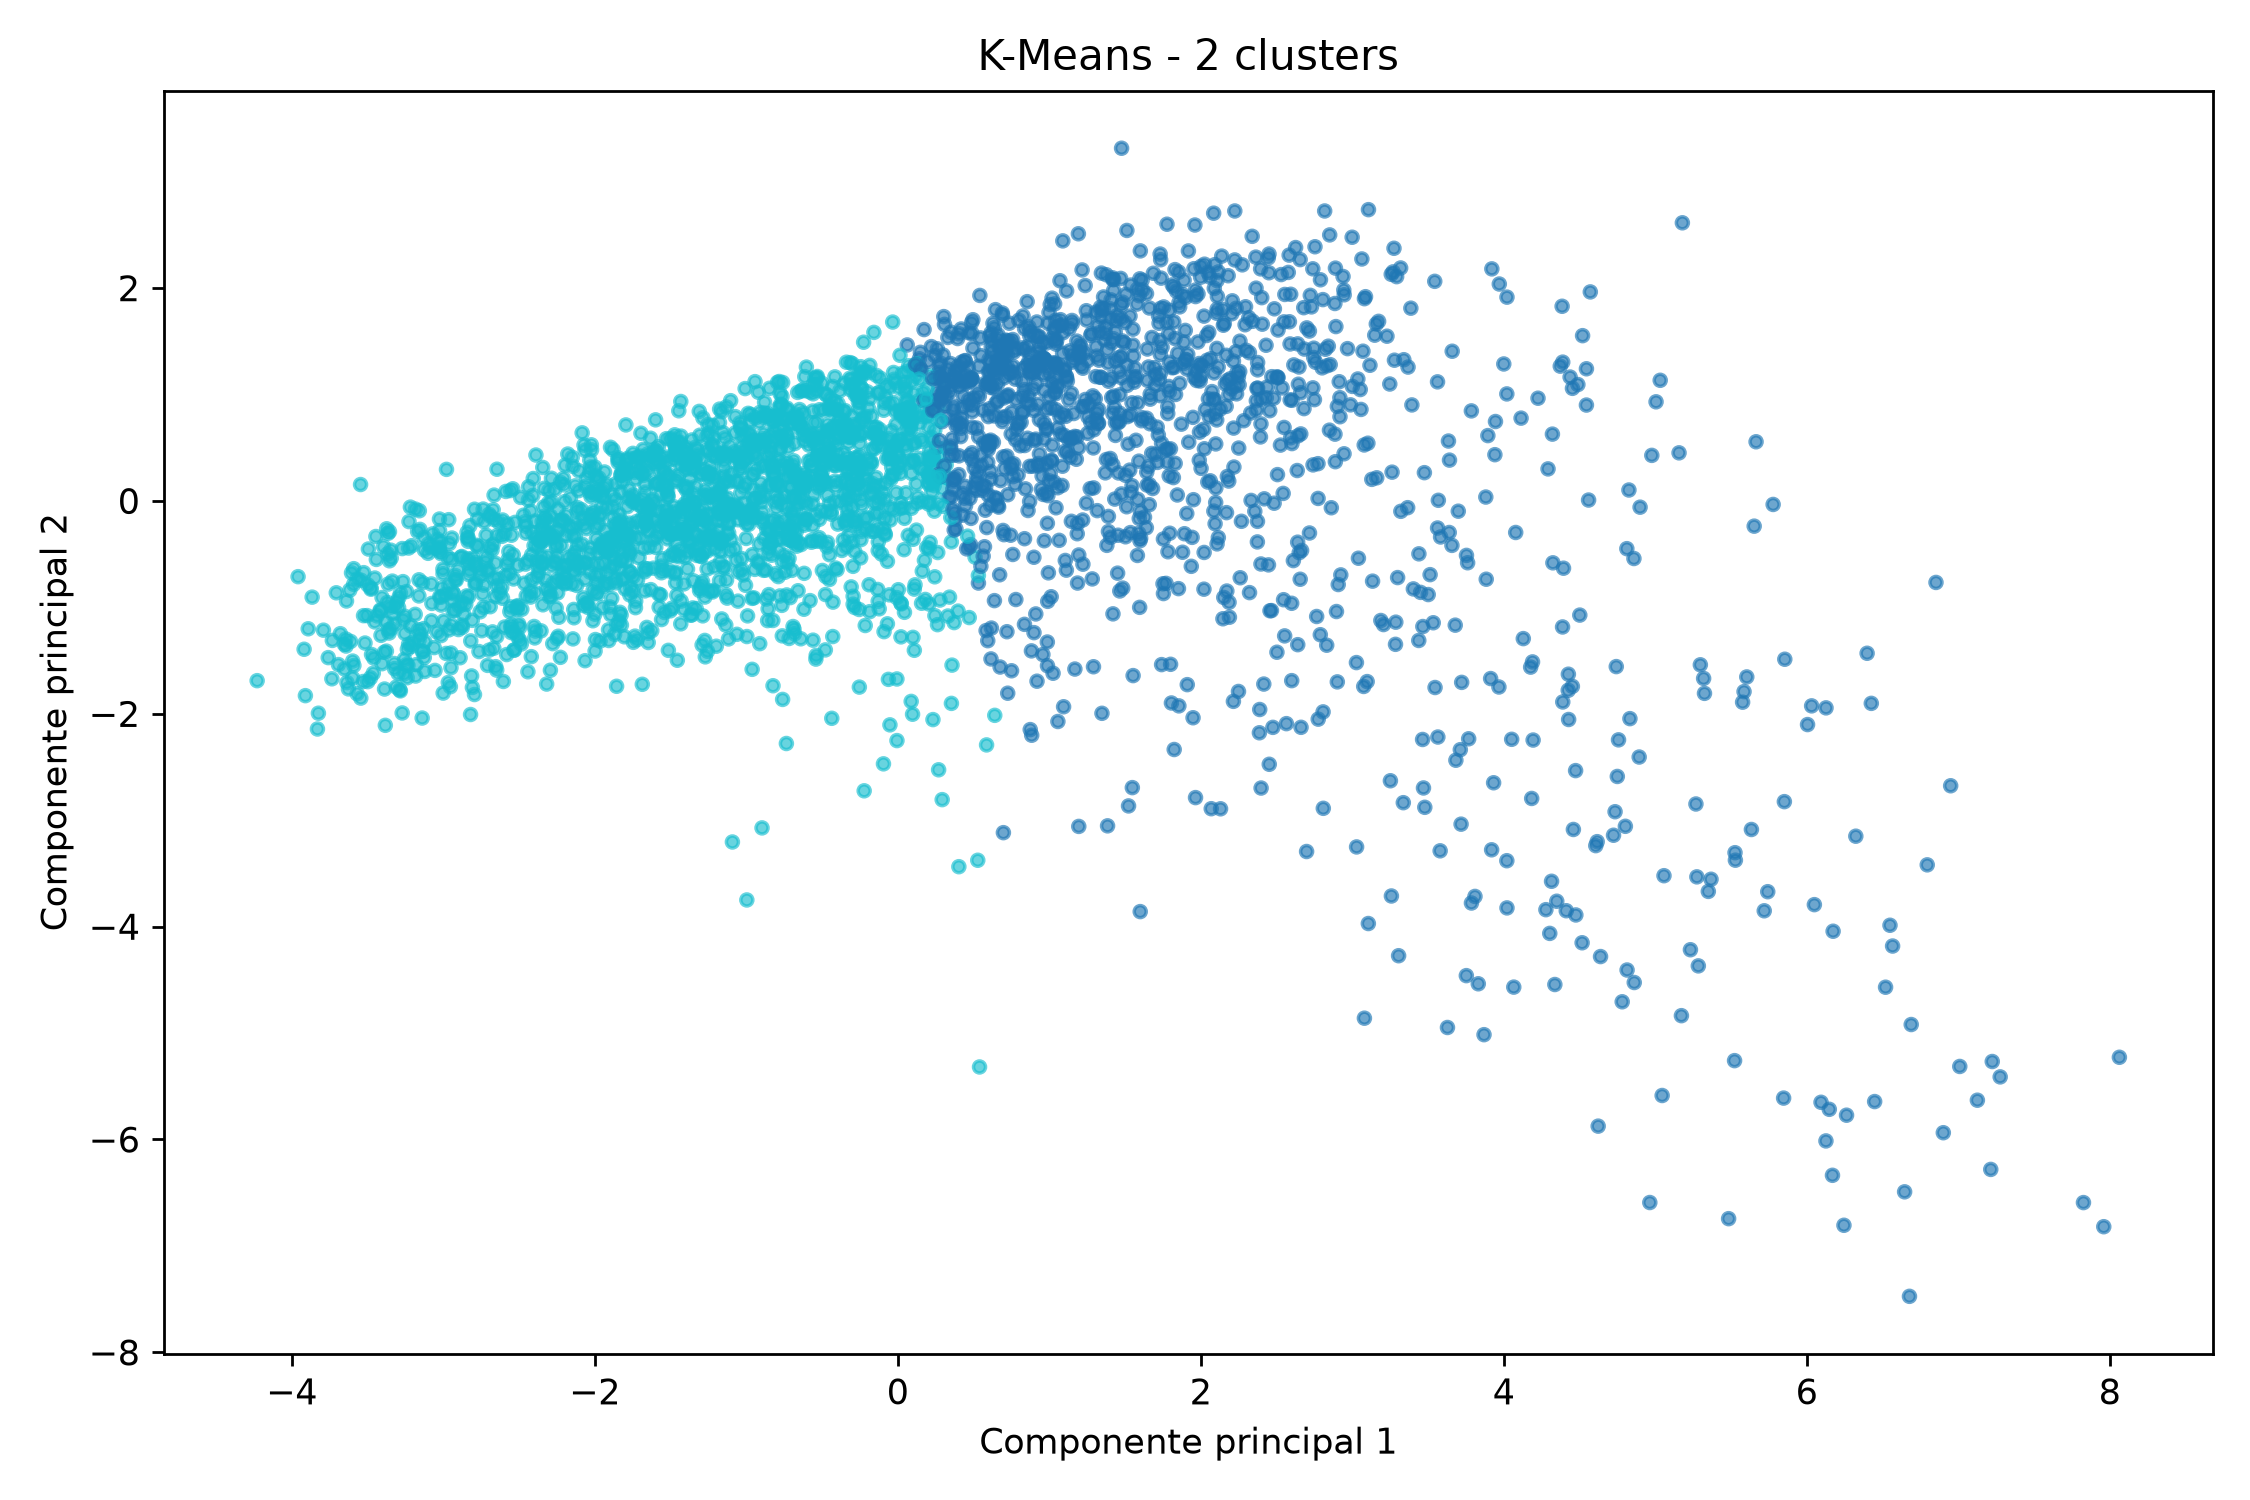

### Proyección PCA — Jerárquico Ward

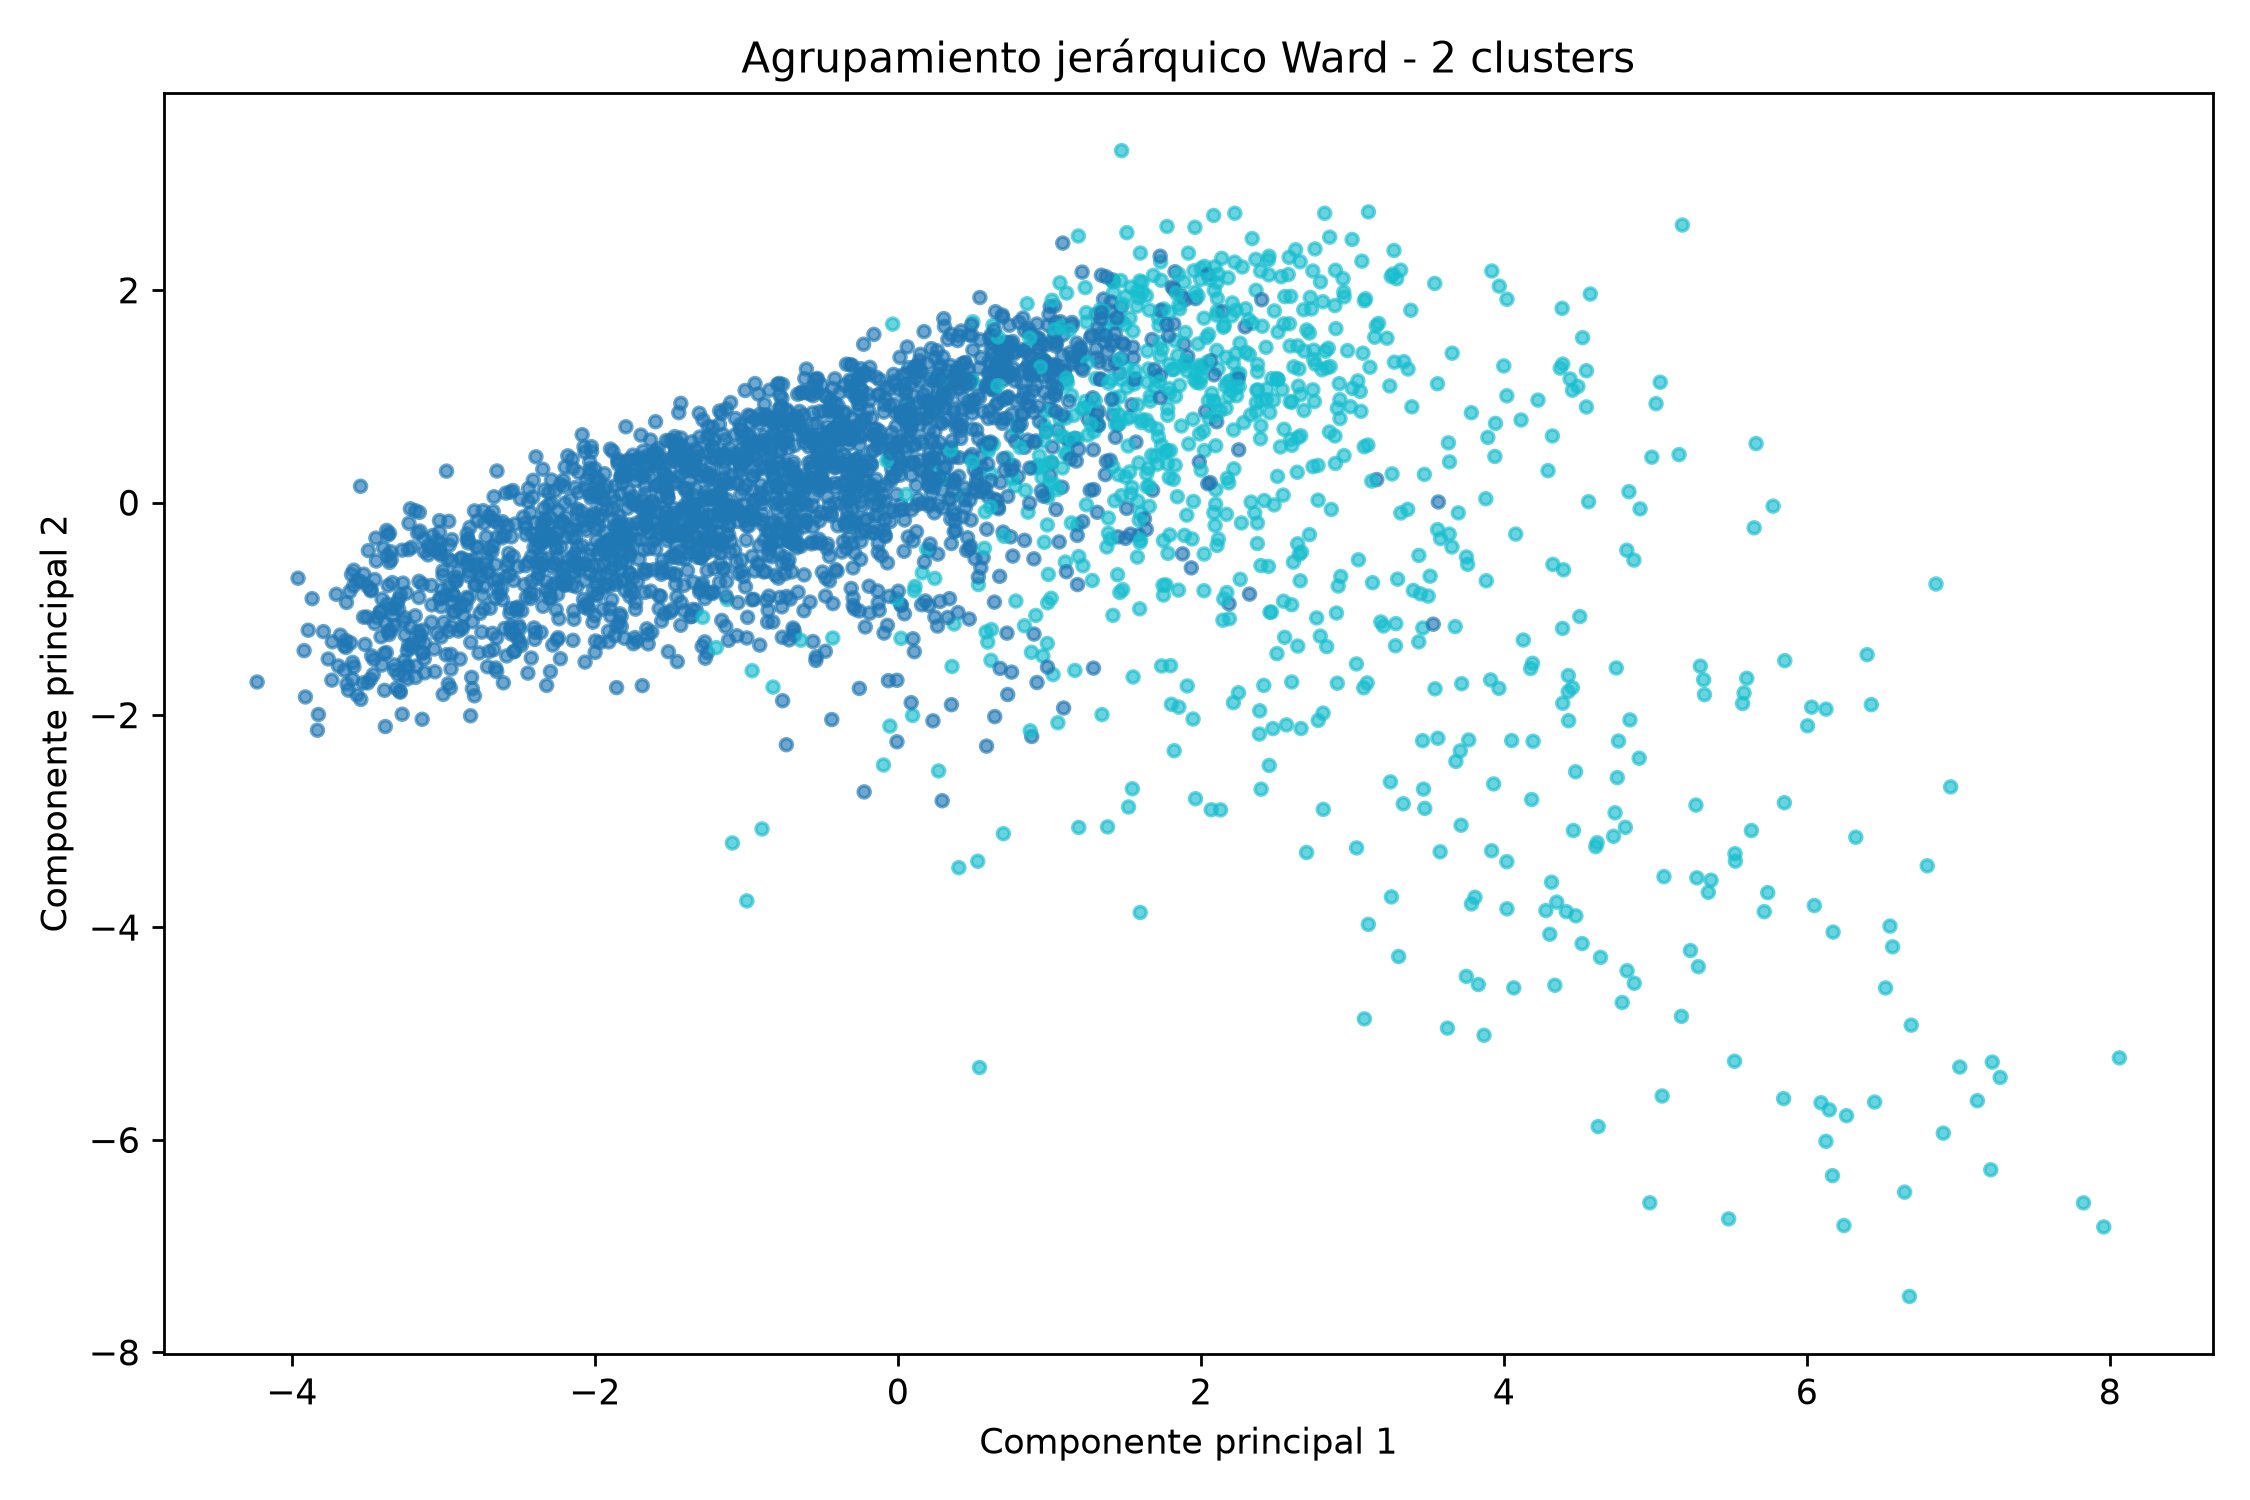

### Proyección PCA — DBSCAN

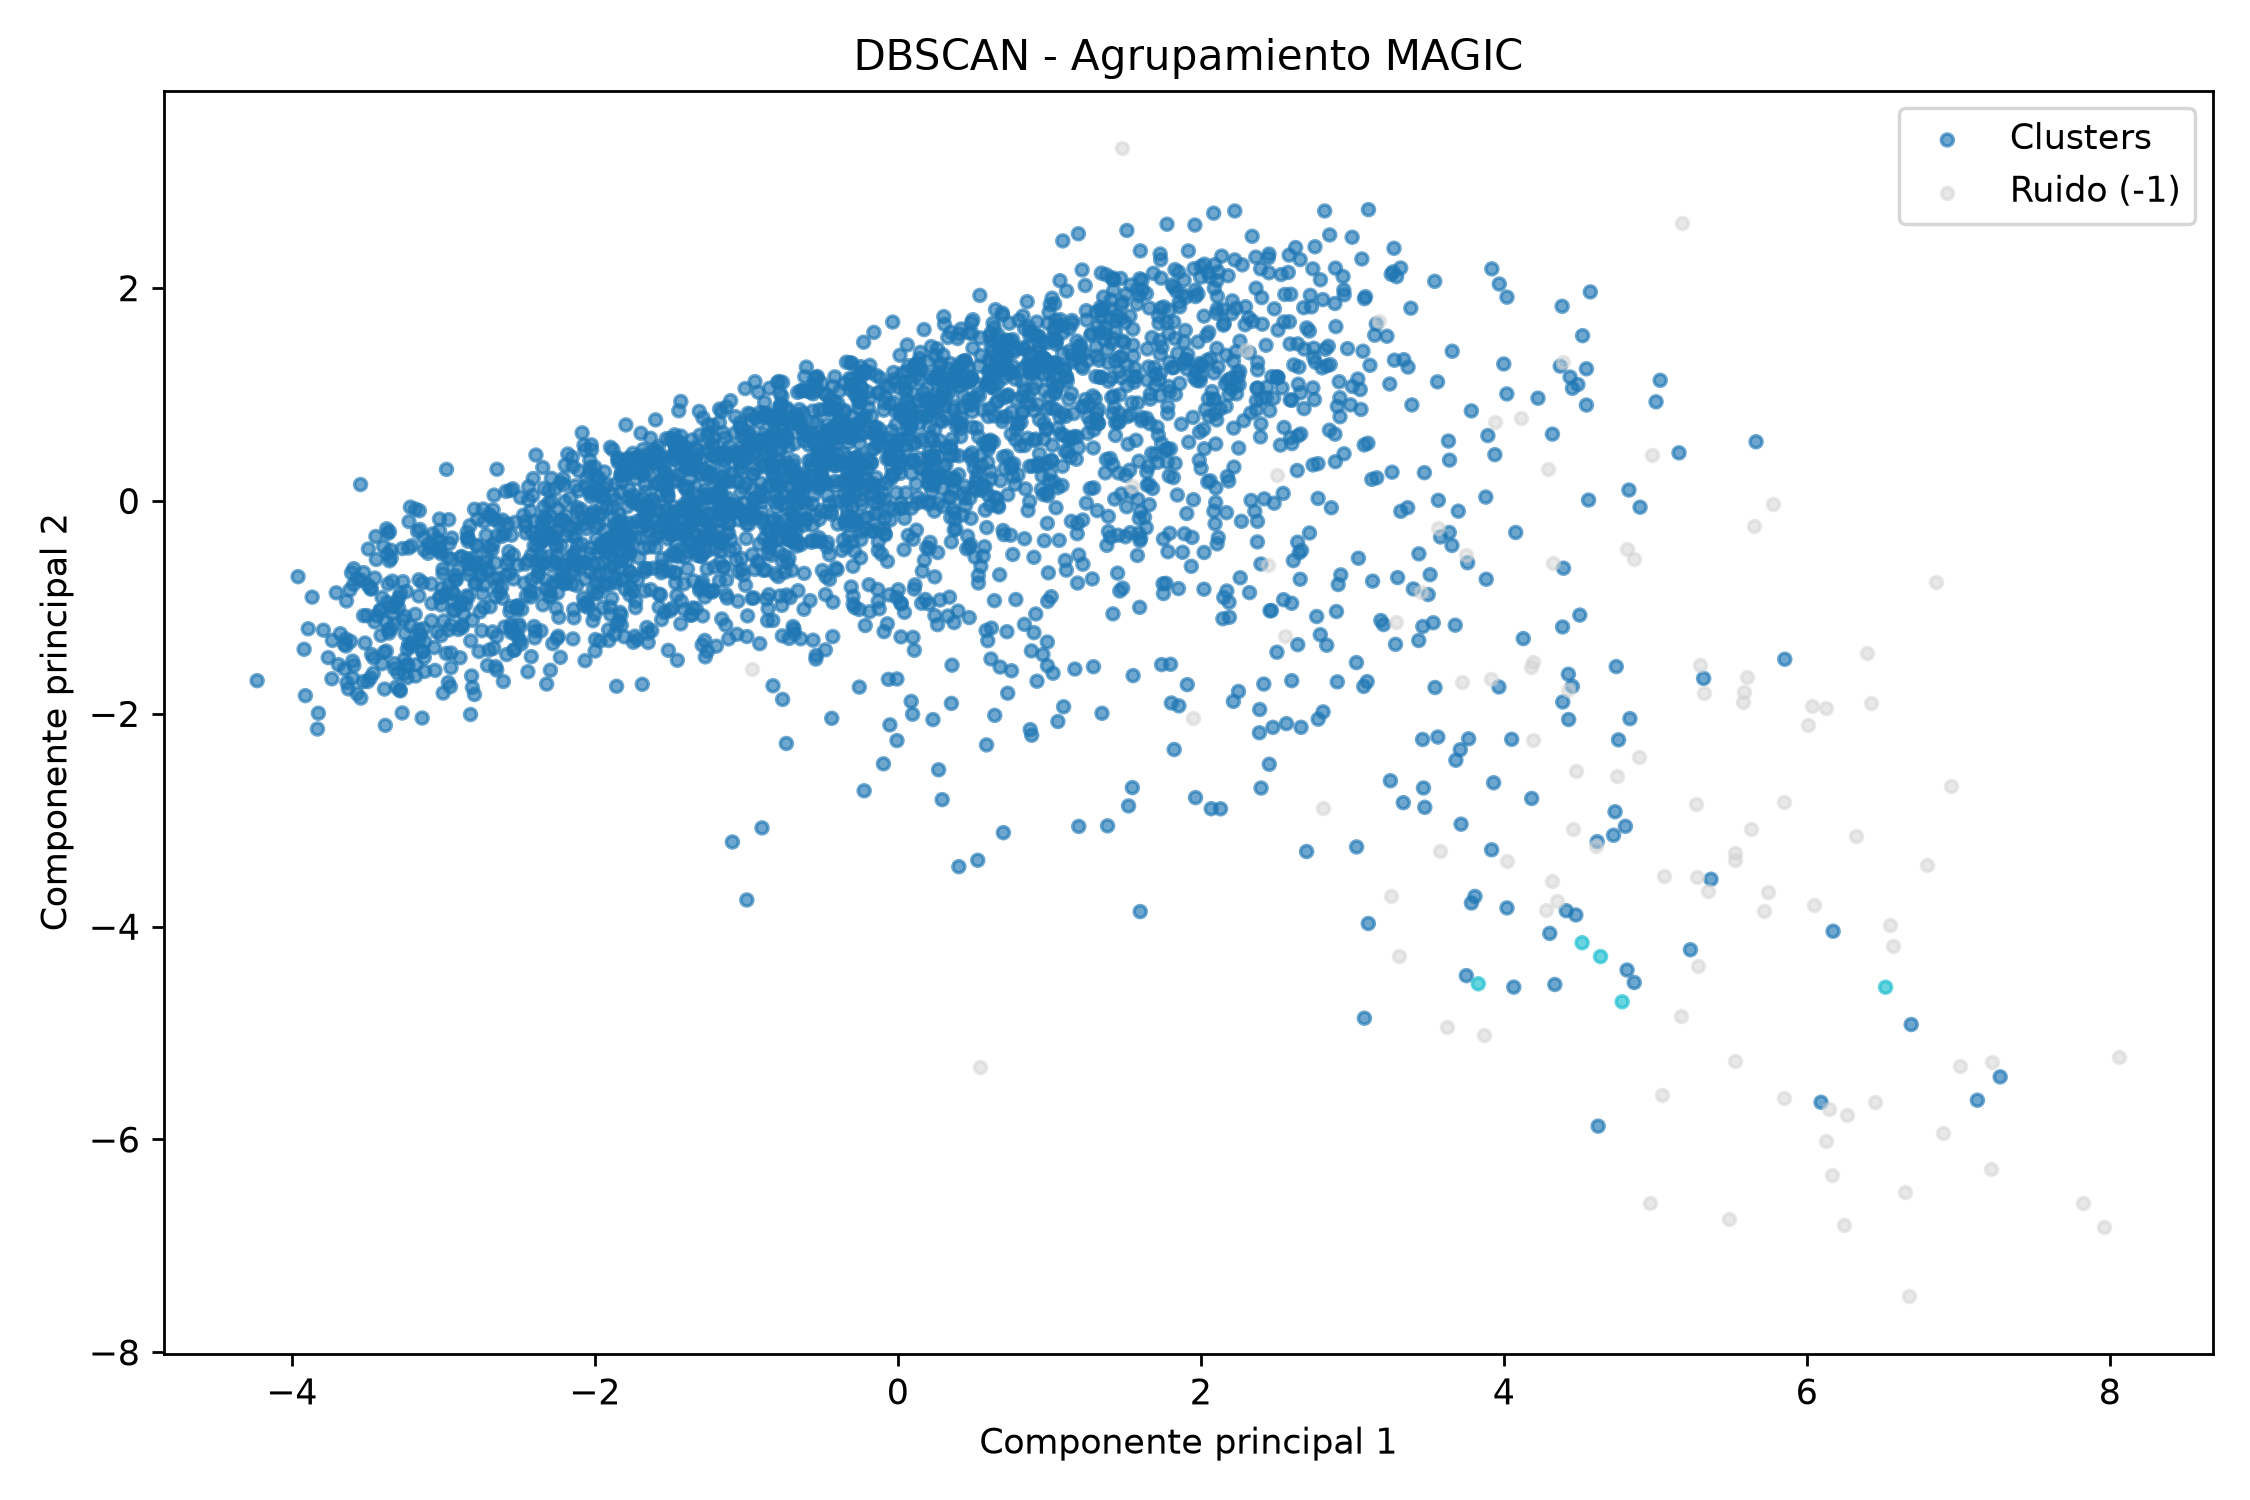

In [15]:
imagenes = {
    "K-Means": BASE / "kmeans" / "clusters_kmeans.png",
    "Jerárquico Ward": BASE / "jerarquico" / "clusters_jerarquico.png",
    "DBSCAN": BASE / "dbscan" / "clusters_dbscan.png",
}

for nombre, ruta in imagenes.items():
    display(Markdown(f"### Proyección PCA — {nombre}"))
    if ruta.is_file():
        display(Image(filename=str(ruta), width=820))
    else:
        print(f"Gráfica opcional no encontrada: {ruta.relative_to(RAIZ)}")

### ¿Por qué algunas observaciones parecen superpuestas?

Una proyección PCA en **dos dimensiones** resume solo parte de la variabilidad total. Dos observaciones que aparecen cerca en el gráfico pueden ser diferentes en las ocho dimensiones no representadas. Por tanto, la superposición visual **no invalida** necesariamente las etiquetas de los clusters, y una separación visual tampoco demuestra coincidencia con gamma/hadrón.

Los resultados cuantitativos —Silhouette, tamaño de grupos, ruido y ARI— ayudan a complementar la interpretación de las imágenes.

## 15. Discusión de resultados

Se compararon tres algoritmos no supervisados sobre una misma muestra reproducible de **3.000 eventos MAGIC** con **10 características estandarizadas**, sin utilizar `Class` durante el ajuste. Las configuraciones de K-Means y Ward se seleccionaron usando **Silhouette** para valores de **K entre 2 y 6**, mientras que DBSCAN exploró distintas escalas de vecindad y mínimos de densidad.

**K-Means** produjo dos grupos de tamaños relativamente equilibrados, con **Silhouette = 0,2855**. La separación fue moderada y las proporciones gamma/hadrón de ambos clusters fueron similares, lo que explica que su **ARI = 0,0039** sea cercano a cero. El algoritmo identificó una partición geométrica, no una clasificación física de los eventos.

**Ward** también seleccionó dos grupos y obtuvo **Silhouette = 0,3193**. Sus clusters presentaron una diferencia mayor en composición gamma, aunque ambos siguieron mezclando las clases. La mejora de Silhouette frente a K-Means no fue acompañada de mejora en todas las métricas: K-Means obtuvo valores más favorables de Calinski-Harabasz y Davies-Bouldin. Esta discrepancia evidencia que la valoración de los agrupamientos depende del criterio de calidad empleado.

**DBSCAN** registró **Silhouette = 0,5450**, pero agrupó **2.900 observaciones** en un cluster, **5** en otro y marcó **95** como ruido. Esta fuerte asimetría y la exclusión del ruido en el cálculo de métricas internas impiden interpretar su Silhouette como evidencia suficiente de una partición más útil. En cambio, la composición del ruido —**90 hadrones de 95 puntos**— plantea la posibilidad de que una parte de los eventos hadrónicos ocupe regiones menos densas del espacio de características bajo la configuración explorada.

Los **ARI próximos a cero** en los tres casos indican que los agrupamientos no recuperaron claramente las etiquetas gamma/hadrón. Esto es compatible con que los algoritmos priorizan similitudes geométricas o de densidad que **no son necesariamente las mismas fronteras utilizadas para distinguir clases con supervisión**. Esa explicación es plausible, pero para identificar las causas concretas haría falta analizar las características de cada grupo y estudiar la sensibilidad a transformaciones y parámetros.

## 16. Conclusiones del punto 2(ii)

1. **Los tres métodos ejecutaron correctamente el agrupamiento**, pero generaron estructuras diferentes incluso al compartir muestra y características.
2. **K-Means** resultó útil para una partición global de tamaños comparables; **Ward** alcanzó el Silhouette más alto entre los métodos que asignaron toda la muestra a grupos de tamaño considerable.
3. **DBSCAN** aportó detección de ruido, pero el agrupamiento seleccionado no representó dos segmentos sustanciales: el segundo cluster contenía apenas **5 registros**.
4. **Las clases físicas no se recuperaron mediante agrupamiento**: todos los ARI fueron bajos, y los grupos principales mezclaron gamma y hadrones.
5. **Ninguna métrica aislada determina el mejor método**. Deben examinarse la separación, la cobertura, los tamaños de grupos, el ruido y el propósito del análisis.

### Limitaciones y trabajo futuro

- La comparación corresponde a **una muestra de 3.000 registros** y una configuración de estandarización.
- El índice Silhouette se calculó con una **submuestra de hasta 1.000 puntos** y, en DBSCAN, solo sobre observaciones agrupadas.
- K-Means y Ward se exploraron con **K = 2 a 6**; DBSCAN con **18 combinaciones** de parámetros. Otros rangos podrían cambiar las conclusiones.
- El hecho de que el ruido esté enriquecido en hadrones **no demuestra una regla estable**; requiere nuevas muestras, análisis de atributos y otras configuraciones.

### Relación con el punto 2(i)

En los experimentos supervisados, la **red neuronal + PSO** obtuvo **F1 = 0,8546** en prueba porque utilizó las etiquetas gamma/hadrón durante el aprendizaje. En los no supervisados, los algoritmos optimizaron criterios de similitud **sin acceder a esas etiquetas**, por lo cual sus grupos no tenían por qué corresponder a las clases reales. **No corresponde comparar F1 y ARI como si fueran la misma medida**: responden a tareas distintas.

## 17. Evidencia y reproducibilidad

Los resultados proceden de estos archivos del proyecto:

- `resultados/punto_2/no_supervisado/kmeans/metricas_kmeans.csv` y `composicion_clusters.csv`.
- `resultados/punto_2/no_supervisado/jerarquico/metricas_jerarquico.csv` y `composicion_clusters.csv`.
- `resultados/punto_2/no_supervisado/dbscan/metricas_dbscan.csv`, `mejor_configuracion.csv` y `composicion_clusters.csv`.
- `resultados/punto_2/no_supervisado/comparacion/resumen_agrupamientos.csv` y `composicion_agrupamientos.csv`.

Para reconstruir esos archivos desde el código original, ejecuta **en este orden desde la raíz del proyecto**:

```powershell
python -m src.punto_2.no_supervisado.kmeans
python -m src.punto_2.no_supervisado.jerarquico
python -m src.punto_2.no_supervisado.dbscan
python -m src.punto_2.no_supervisado.comparar_agrupamientos
```

> **Este notebook no reemplaza los scripts ni reentrena los agrupamientos**. Presenta y documenta sus resultados, por lo que puedes utilizarlo como evidencia explicada en la exposición junto a los notebooks `01`, `02` y `03`.